# 01 - Data acquisition & EDA
UCI Heart Disease, Cleveland subset (303 patients, 13 attributes + `num`). `num` 0 = no disease, 1-4 = disease, binarised into `target`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 140)

## 1. Acquire
The download script fetches the file from UCI (falling back to the zip bundle) and writes the cleaned CSV.

In [2]:
from heart_risk import config
from heart_risk.data import download_raw, load_raw, clean, missing_report
if not config.RAW_FILE.exists():
    download_raw()
raw = load_raw()
print(raw.shape)
raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 2. Data quality
Missing values are encoded as `?` in the raw file.

In [3]:
print('Missing per column:', missing_report(raw).to_dict())
print('Duplicate rows:', raw.duplicated().sum())
raw.describe().T

Missing per column: {'ca': 4, 'thal': 2}
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


Only `ca` (4) and `thal` (2) are missing (<2% of rows). Rather than dropping rows from an already small dataset, they are kept as NaN and imputed **inside** the model pipeline (median / most-frequent), so the imputation statistics are learned from the training fold only and re-applied identically at serving time.

In [4]:
df = clean(raw)
df.to_csv(config.CLEAN_FILE, index=False)
df[config.TARGET].value_counts()

target
0    164
1    139
Name: count, dtype: int64

## 3. Visual exploration

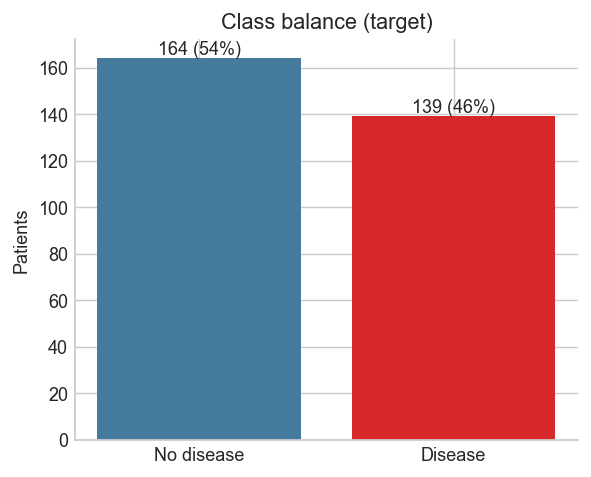

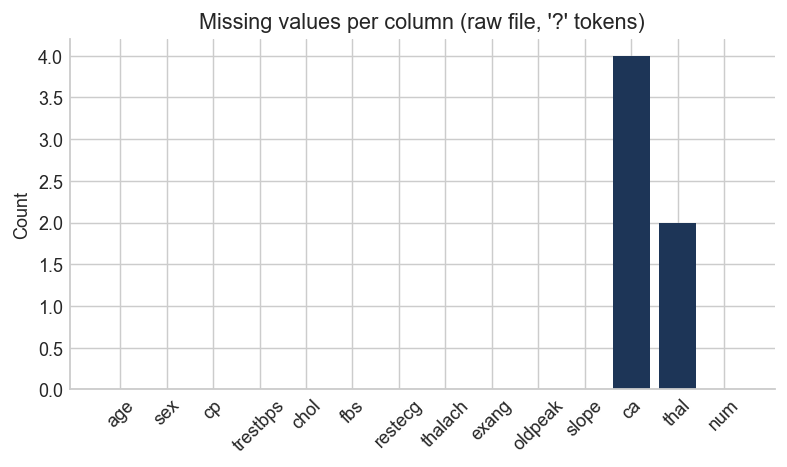

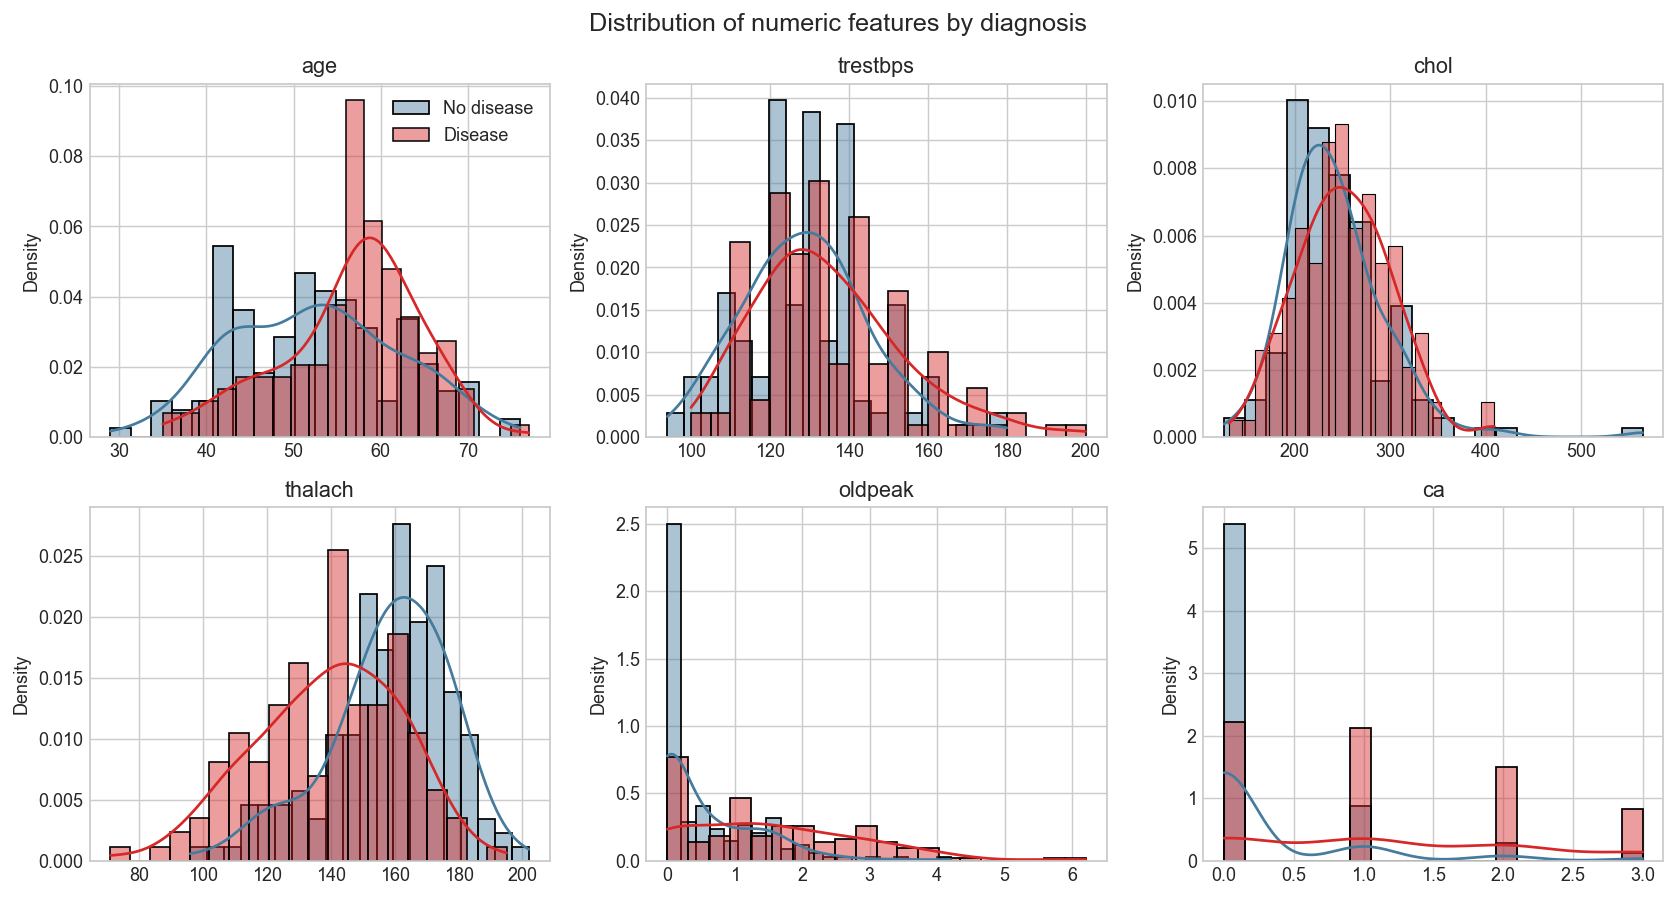

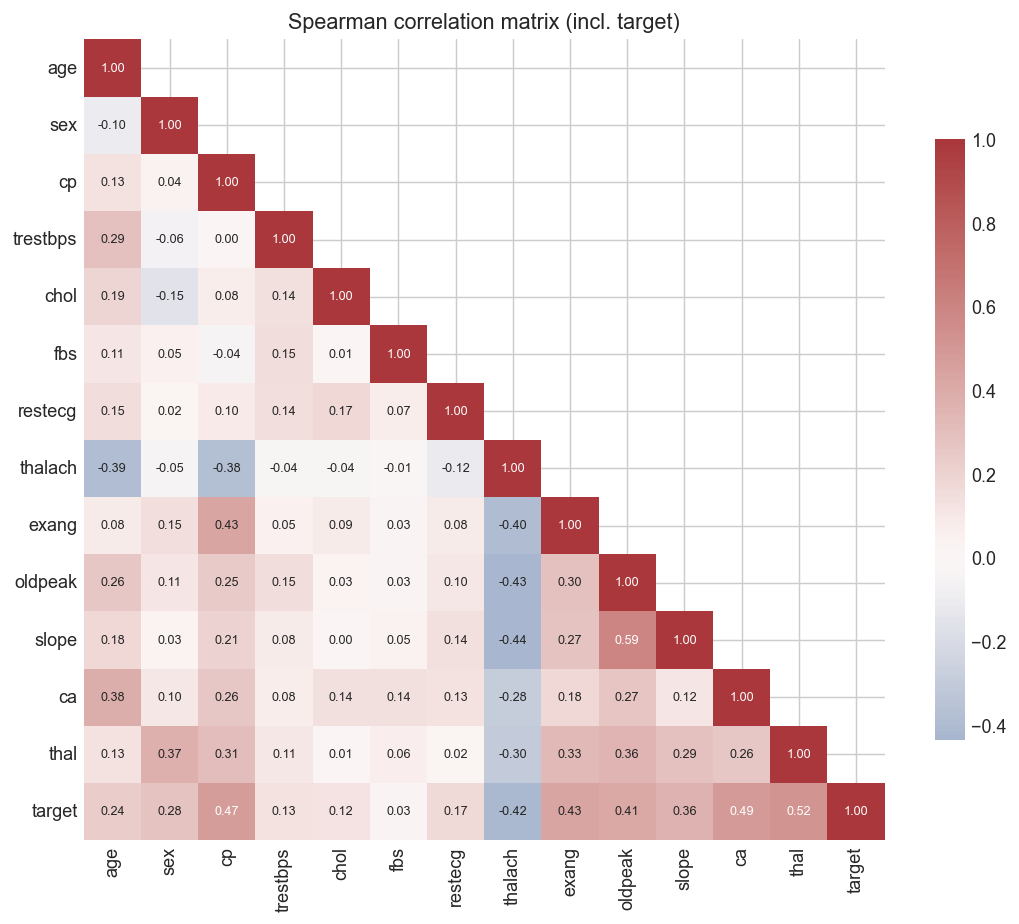

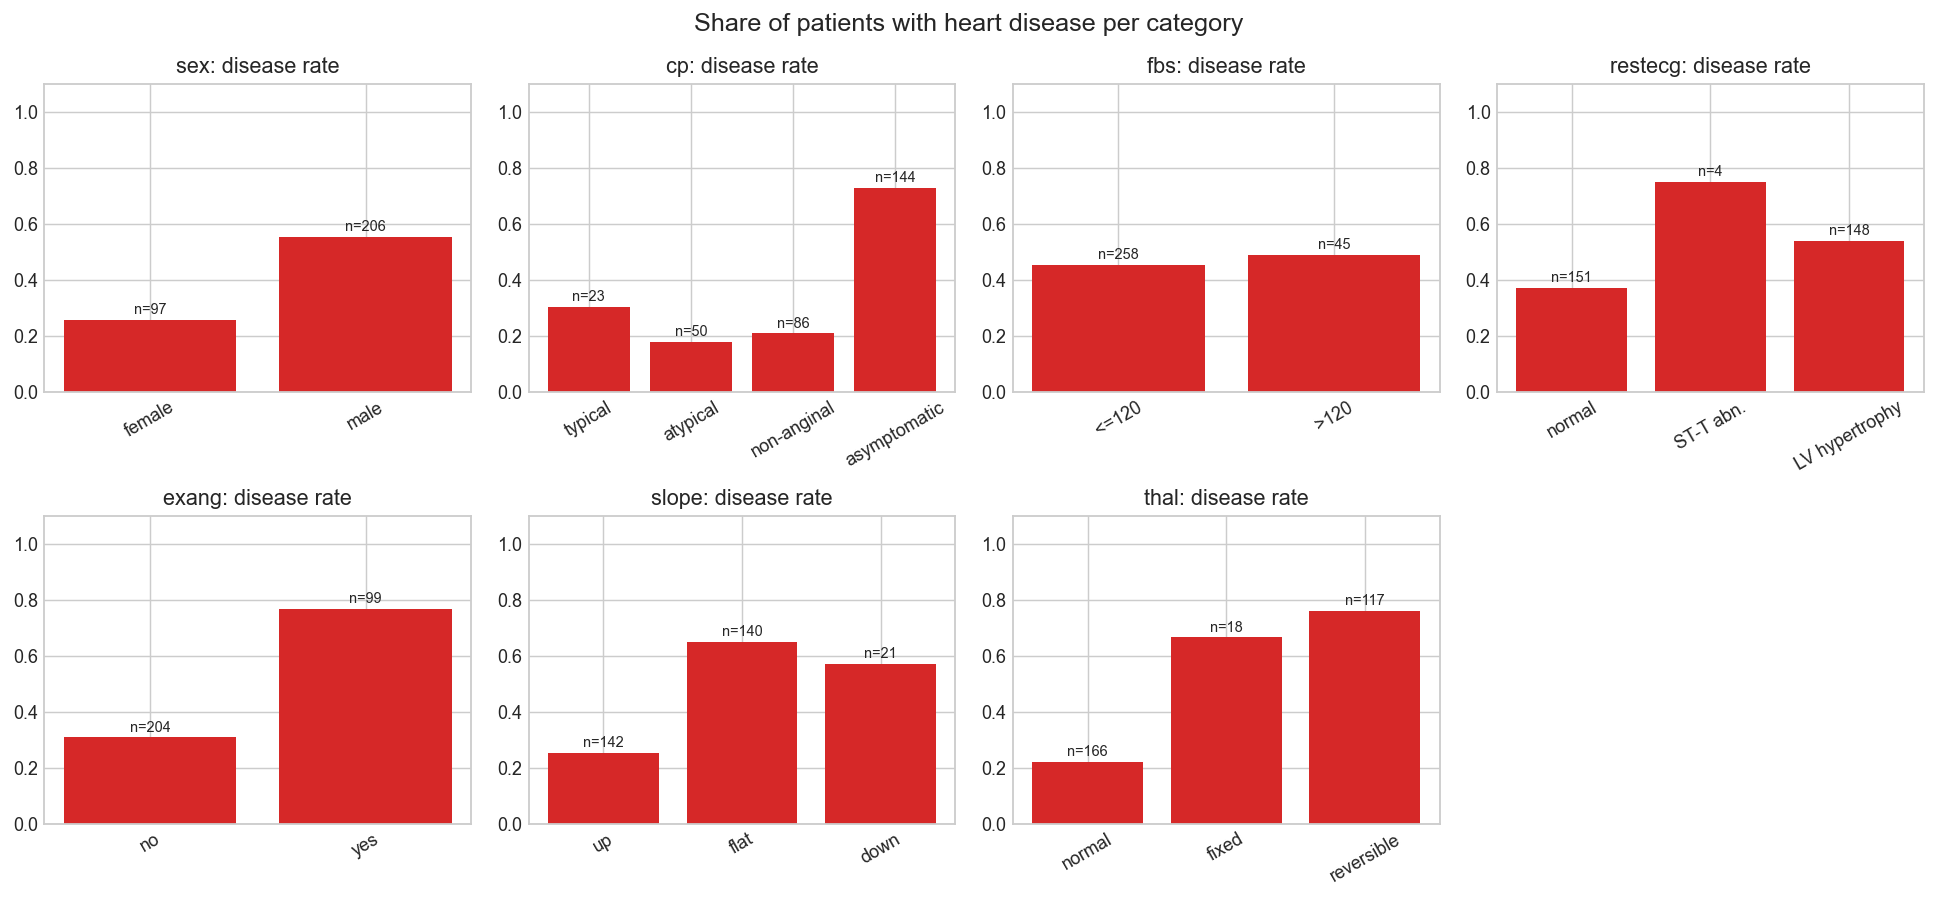

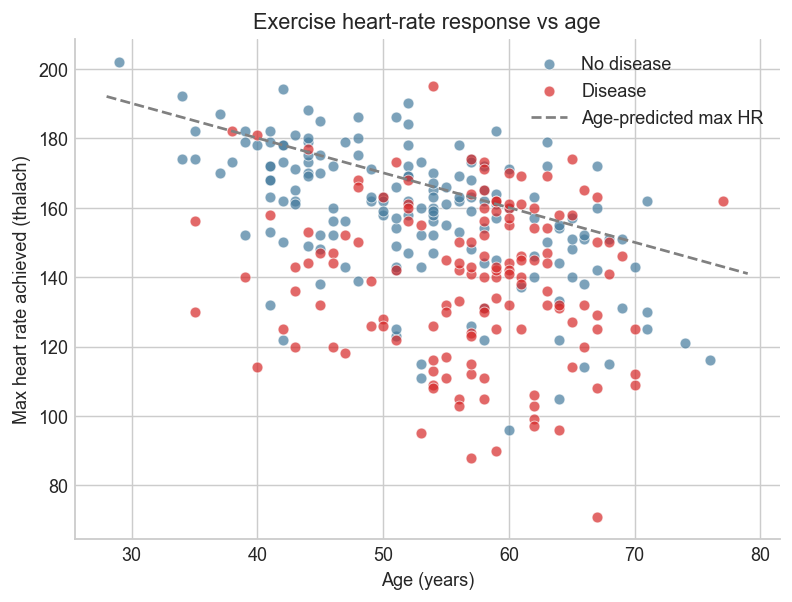

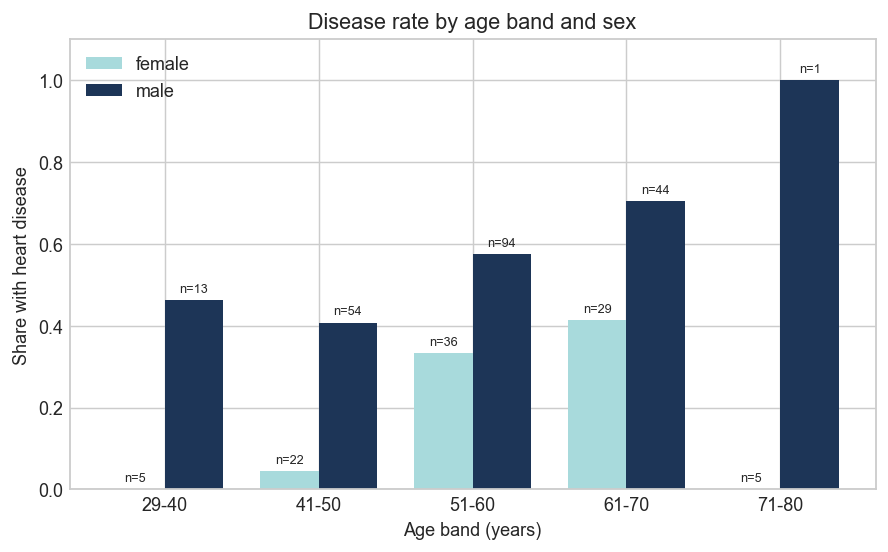

In [5]:
from IPython.display import Image, display
from heart_risk.eda import run_eda
figs = run_eda()
for name, path in figs.items():
    display(Image(filename=str(path)))

## 4. Findings that drive modelling
* **Class balance** is 54% / 46%: mild, so accuracy is meaningful, but ROC-AUC is used as the primary selection metric and `class_weight='balanced'` is searched.
* **Strongest signals**: `thal` (reversible defect), `ca` (vessels coloured), `cp` = asymptomatic, `exang`, `oldpeak`, and *low* `thalach` (|Spearman rho| 0.4-0.5 with the target).
* `chol`, `fbs` and `trestbps` are weak on their own, and `chol` / `oldpeak` are right-skewed, so numeric features use a **RobustScaler** (median / IQR).
* Diseased patients reach a lower share of their age-predicted max heart rate (scatter plot), motivating `hr_pct_of_max = thalach / (220 - age)`; blood pressure is combined with heart rate into the **rate-pressure product** (cardiac workload).
* Men have a higher disease rate than women in every age band, and up to 70 risk rises with age (age-band chart; 71-80 has only 6 patients). With `ca` being a top signal, this motivates `vessel_age_burden = (age / 50) * (1 + ca)`.
* `cp`, `restecg`, `slope`, `thal` are nominal codes, so they are one-hot encoded rather than treated as numbers. `restecg = 1` has only 4 rows, so the encoder uses `handle_unknown='ignore'`.

In [6]:
df.groupby(config.TARGET)[['age','thalach','oldpeak','ca']].mean().round(2)

,age,thalach,oldpeak,ca
target,,,,
0,52.59,158.38,0.59,0.27
1,56.63,139.26,1.57,1.14
